# Where Does Home Field Matter Most: NFL or College Football?

**Part 2 of the project.** Part 1 ([`analysis.ipynb`](analysis.ipynb), [`deep_dive.ipynb`](deep_dive.ipynb)) measured home field in the NFL. This notebook repeats it for college football (FBS) and compares the two leagues.

**The trap:** raw home win % is not a fair yardstick between leagues.
- In college, strong schools often schedule weaker visitors at home, which inflates home records.
- College has bigger talent gaps, so many games are decided before kickoff no matter where they're played.

So the comparison is done twice: first with raw win %, then with Part 1's rating model, which removes team strength and gives the home edge **in points between two equally good teams**.

Steps: pull from the CollegeFootballData.com API → clean → load into Postgres (`cfb` schema + `compare` view) → SQL → raw statistics → strength-adjusted statistics → charts.

## 1. Pull the data
Every regular-season college game 2015–2025 from `https://api.collegefootballdata.com/games` (one call per season). The free API key lives in `.env` as `CFBD_API_KEY` and is never printed. Column names are converted from camelCase to snake_case (`homeTeam` → `home_team`). The helper code is in [`cfb.py`](cfb.py).

The raw pull is saved to `data/`, so re-running the notebook doesn't call the API again.

In [1]:
import os
import math
from statistics import NormalDist
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
import cfb
import hfa

os.makedirs("data", exist_ok=True)
RAW = "data/raw_cfb_games.csv"
if os.path.exists(RAW):
    raw = pd.read_csv(RAW, low_memory=False)
else:
    raw = cfb.pull_games(2015, 2025)
    raw.to_csv(RAW, index=False)
print(raw.shape)
raw.groupby("home_classification").size()   # FBS, FCS, Division II and III are all in the pull

(25301, 34)


home_classification
fbs    9061
fcs    6939
ii     4403
iii    4826
dtype: int64

## 2. Clean the data
| Rule | Why |
| --- | --- |
| Both teams FBS | Top division vs. top division (no FCS or lower-division visitors) |
| Drop neutral sites | Nobody is really "home" (kickoff classics, rivalry games at NFL stadiums) |
| Completed games only | Some 2020 games were cancelled |
| Drop ties | Not a win or a loss (rare since overtime came in) |
| Drop conference title games | The higher seed hosts: the college version of the playoffs, which Part 1 also excluded. The API only labels them from 2022, so earlier ones are found by date (see `cfb.title_game_ids`) |
| Keep only the home team's usual stadium | Same rule as Part 1: drops hurricane moves, second "home" stadiums and mislabelled rows (and, because some venue labels in the API are inconsistent, a few genuine home games) |

Same new columns as the NFL table (`home_win`, `margin`, `covid_season`) plus `conference_game` (1 = both teams in the same conference). The NFL table needs no stadium filter: for 2015–2025, every NFL game marked "Home" was at the home team's usual stadium.

In [2]:
games = cfb.clean(raw)
print(f"{len(games):,} games, {games.home_team.nunique()} teams, {games.conference_game.sum():,} conference games")
games.groupby("season").agg(games=("game_id", "size"), conference=("conference_game", "sum")).T

7,586 games, 137 teams, 5,580 conference games


season,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
games,697,688,712,702,709,495,700,711,724,713,735
conference,503,507,518,509,510,437,504,512,531,512,537


## 3. Load into the database
College games go in their own `cfb` schema; the comparison view lives in a `compare` schema. `nfl.games` and the dashboard's other tables are not touched. The view is dropped first because it depends on `cfb.games`, then rebuilt from [`sql/05_create_league_view.sql`](sql/05_create_league_view.sql).

In [3]:
load_dotenv()
engine = create_engine(os.environ["DB_URL"])
with engine.begin() as conn:
    conn.execute(text("CREATE SCHEMA IF NOT EXISTS cfb"))
    conn.execute(text("DROP VIEW IF EXISTS compare.league_games"))
games.to_sql("games", engine, schema="cfb", if_exists="replace", index=False)
with engine.begin() as conn:
    conn.execute(text(open("sql/05_create_league_view.sql").read()))
pd.read_sql("SELECT league, COUNT(*) AS games FROM compare.league_games GROUP BY league ORDER BY league", engine)

,league,games
0,College (all FBS),7586
1,College (conference),5580
2,NFL,2837


## 4. First look with SQL (raw win %)

In [4]:
def run(file):
    with open(f"sql/{file}") as f:
        return pd.read_sql(f.read(), engine)

compare = run("06_league_compare.sql")
by_season = run("07_league_by_season.sql")
fans = run("08_league_fan_effect.sql")
crowds = run("09_cfb_2020_crowds.sql")
compare

,league,games,home_win_pct,edge_over_50,avg_home_margin
0,College (all FBS),7586,58.6,8.6,4.3
1,College (conference),5580,55.6,5.6,2.4
2,NFL,2837,54.6,4.6,1.8


In [5]:
by_season.pivot(index="season", columns="league", values="home_win_pct")

league,College (all FBS),College (conference),NFL
season,,,
2015,56.5,53.3,53.8
2016,58.4,55.6,57.8
2017,57.9,54.2,57.0
2018,59.8,56.0,60.6
2019,60.1,57.8,52.0
2020,56.8,55.8,50.4
2021,58.1,55.6,51.1
2022,58.5,54.5,56.7
2023,58.4,56.7,55.8


In [6]:
fans

,league,normal_games,games_2020,normal_home_win_pct,home_win_pct_2020,drop_in_2020,pct_of_edge_lost
0,NFL,2585.0,252.0,55.0,50.4,4.7,92.0
1,College (conference),5143.0,437.0,55.6,55.8,-0.3,-5.0
2,College (all FBS),7091.0,495.0,58.7,56.8,1.9,22.0


Raw numbers say college home teams win a lot more (58.6% across all FBS games), and that 2020 hurt the NFL but not college conference games. **Both of those readings are misleading** once team strength is removed (section 6): the first is mostly scheduling, and the second hides a drop of similar size in college.

## 5. Raw win %: is it more than luck?
- **95% range** for each group's home win % (`proportion_confint`, Wilson method).
- **p-values** (`proportions_ztest`). Below 0.05 = unlikely to be luck.

In [7]:
rows = pd.read_sql("SELECT league, covid_season, home_win FROM compare.league_games", engine)

def ci(g):
    lo, hi = proportion_confint(g.sum(), len(g), method="wilson")
    return pd.Series({"games": len(g), "home_win_pct": 100 * g.mean(), "low_95": 100 * lo, "high_95": 100 * hi})

rows.groupby("league").home_win.apply(ci).unstack().round(1)

,games,home_win_pct,low_95,high_95
league,,,,
College (all FBS),7586.0,58.6,57.4,59.7
College (conference),5580.0,55.6,54.3,56.9
NFL,2837.0,54.6,52.8,56.5


In [8]:
def p_value(a, b):
    return proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])[1]

league = {name: g for name, g in rows.groupby("league")}
tests = [("NFL vs. college conference", p_value(league["NFL"].home_win, league["College (conference)"].home_win))]
for name, g in league.items():
    tests.append((f"{name}: normal vs. 2020", p_value(g[g.covid_season == 0].home_win, g[g.covid_season == 1].home_win)))
pd.DataFrame(tests, columns=["test", "p_value"]).round(3)

,test,p_value
0,NFL vs. college conference,0.404
1,College (all FBS): normal vs. 2020,0.404
2,College (conference): normal vs. 2020,0.915
3,NFL: normal vs. 2020,0.157


## 6. Remove team strength
Part 1's rating model ([`hfa.py`](hfa.py)), fit separately each season: `home margin = home edge + rating[home] − rating[away]`. For every game, `adj_edge` = home margin minus the strength gap. Its average is the home edge in points between two equally good teams.

College ratings are fit on all FBS games, so conference games borrow strength information from non-conference games.

**Why raw win % misleads, in one table:** the average strength gap (home minus away, in points). In non-conference games the home team is usually the stronger school; in conference games home and away teams are balanced.

In [9]:
nfl = cfb.add_strength_adjusted_edge(pd.read_sql("SELECT * FROM nfl.games", engine))
col = cfb.add_strength_adjusted_edge(pd.read_sql("SELECT * FROM cfb.games", engine))
groups = {
    "NFL": nfl,
    "College (conference)": col[col.conference_game == 1],
    "College (non-conference)": col[col.conference_game == 0],
    "College (all FBS)": col,
}
pd.DataFrame({name: {"games": len(d),
                     "home_win_pct": round(100 * d.home_win.mean(), 1),
                     "avg_strength_gap_pts": round(d.strength_gap.mean(), 1),
                     "avg_size_of_gap_pts": round(d.strength_gap.abs().mean(), 1)}
              for name, d in groups.items()}).T

,games,home_win_pct,avg_strength_gap_pts,avg_size_of_gap_pts
NFL,2837.0,54.6,0.0,6.7
College (conference),5580.0,55.6,0.1,12.2
College (non-conference),2006.0,66.8,7.3,16.6
College (all FBS),7586.0,58.6,2.0,13.4


Non-conference home teams start about 7 points stronger, which is what pushes the all-FBS win % up. Conference games are **not** evenly matched (the typical gap is still large), but they are balanced between home and away, which is what matters here.

Next: the home edge in points for each group, normal seasons vs. 2020, straight from the rating model ([`cfb.season_home_edges`](cfb.py)). Each season gets its own estimate with a proper standard error (one that accounts for team ratings being estimated too, which matters in 2020 when teams played few games). Normal seasons are then pooled, giving more weight to more precise seasons, the same way Part 1 did. College conference and non-conference games each get their own home edge, while every game informs the team ratings. (In 2020 the college schedule split into four groups of teams that never played each other; the model handles that, because the home edge is still measured within each group.)

`equal_team_win_pct` turns points into "how often the home team would win if both teams were equally good" (using how much game results vary around the model). That's a fair win % to compare between leagues.

In [10]:
season_edges = pd.concat([
    cfb.season_home_edges(nfl).assign(group="NFL"),
    cfb.season_home_edges(col, "conference_game", {1: "College (conference)", 0: "College (non-conference)"}),
    cfb.season_home_edges(col).assign(group="College (all FBS)"),
], ignore_index=True)

def summary(e):
    p = cfb.pool(e)
    return pd.Series({"games": int(p.games), "home_edge_pts": p.home_edge, "se": p.se,
                      "low_95": p.home_edge - 1.96 * p.se, "high_95": p.home_edge + 1.96 * p.se,
                      "equal_team_win_pct": 100 * NormalDist().cdf(p.home_edge / p.sigma)})

order = ["NFL", "College (conference)", "College (non-conference)", "College (all FBS)"]
adj = pd.DataFrame([{"group": g, "period": per, **summary(e[(e.season == 2020) == (per == "2020")])}
                    for g, e in season_edges.groupby("group") for per in ["normal", "2020"]])
adj["group"] = pd.Categorical(adj.group, order); adj = adj.sort_values(["group", "period"], ascending=[True, False])
adj.round(2)

,group,period,games,home_edge_pts,se,low_95,high_95,equal_team_win_pct
6,NFL,normal,2585.0,1.89,0.24,1.41,2.36,56.15
7,NFL,2020,252.0,0.13,0.78,-1.40,1.65,50.42
2,College (conference),normal,5143.0,2.38,0.20,1.99,2.78,56.64
3,College (conference),2020,437.0,0.97,0.71,-0.41,2.36,52.70
4,College (non-conference),normal,1948.0,2.39,0.38,1.65,3.13,56.66
5,College (non-conference),2020,58.0,-2.00,2.51,-6.93,2.93,44.44
0,College (all FBS),normal,7091.0,2.38,0.18,2.04,2.73,56.64
1,College (all FBS),2020,495.0,0.76,0.68,-0.58,2.10,52.11


In [11]:
A = adj.set_index(["group", "period"])

def diff_test(a, b):
    """Difference of two estimates and its two-sided p-value (z-test on independent estimates)."""
    d, se = a.home_edge_pts - b.home_edge_pts, math.hypot(a.se, b.se)
    return d, se, hfa.norm_p(d / se)

nfl_drop = diff_test(A.loc[("NFL", "normal")], A.loc[("NFL", "2020")])
conf_drop = diff_test(A.loc[("College (conference)", "normal")], A.loc[("College (conference)", "2020")])
did = nfl_drop[0] - conf_drop[0], math.hypot(nfl_drop[1], conf_drop[1])
adj_tests = pd.DataFrame([
    ("Normal seasons: college conference minus NFL", *diff_test(A.loc[("College (conference)", "normal")], A.loc[("NFL", "normal")])),
    ("NFL: normal minus 2020", *nfl_drop),
    ("College conference: normal minus 2020", *conf_drop),
    ("College all FBS: normal minus 2020", *diff_test(A.loc[("College (all FBS)", "normal")], A.loc[("College (all FBS)", "2020")])),
    ("Did the NFL lose more than college? (NFL drop minus college drop)", did[0], did[1], hfa.norm_p(did[0] / did[1])),
], columns=["test", "difference_pts", "se", "p_value"])
adj_tests.round(3)

,test,difference_pts,se,p_value
0,Normal seasons: college conference minus NFL,0.496,0.314,0.114
1,NFL: normal minus 2020,1.759,0.814,0.031
2,College conference: normal minus 2020,1.412,0.735,0.055
3,College all FBS: normal minus 2020,1.626,0.705,0.021
4,Did the NFL lose more than college? (NFL drop ...,0.347,1.097,0.752


## 7. College 2020: did crowd size matter?
College attendance in 2020 ran from zero to about 27,000 (normal seasons: median about 36,000), so it allows a direct check. Raw numbers come from [`sql/09_cfb_2020_crowds.sql`](sql/09_cfb_2020_crowds.sql); the strength-adjusted edge per game and a straight-line trend come from pandas and statsmodels. (These ranges treat 2020 team ratings as known, so they are a bit too narrow.)

Two cautions: crowd size in 2020 mostly reflects **conference policy** (SEC, Big 12 and ACC schools allowed fans; the Big Ten, Pac-12, MAC and Mountain West mostly didn't), so the trend is also checked within conferences. And an attendance of 0 can sometimes mean "not recorded" rather than an empty stadium.

In [12]:
crowds

,crowd,games,home_win_pct,avg_home_margin
0,"1) 1,000 or fewer",180,53.3,0.7
1,"2) 1,001 to 10,000",153,56.2,0.9
2,"3) more than 10,000",144,63.2,6.0


In [13]:
c20 = col[(col.season == 2020) & col.attendance.notna()].copy()
c20["crowd"] = pd.cut(c20.attendance, [-1, 1000, 10000, 1e6], labels=["1,000 or fewer", "1,001 to 10,000", "more than 10,000"])
by_crowd = c20.groupby("crowd", observed=True).adj_edge.apply(lambda s: pd.Series(hfa.mean_ci(s)[:3], index=["home_edge_pts", "low_95", "high_95"])).unstack()
c20["fans_10k"] = c20.attendance / 10000
trend = smf.ols("adj_edge ~ fans_10k", c20).fit()
print(f"Each extra 10,000 fans: {trend.params['fans_10k']:+.2f} pts (p = {trend.pvalues['fans_10k']:.2f})")
same_conf = smf.ols("adj_edge ~ fans_10k + C(home_conference)", c20).fit()
print(f"...comparing games within the same conference: {same_conf.params['fans_10k']:+.2f} pts (p = {same_conf.pvalues['fans_10k']:.2f})")
by_crowd.round(2)

Each extra 10,000 fans: +0.68 pts (p = 0.42)
...comparing games within the same conference: +0.30 pts (p = 0.83)


,home_edge_pts,low_95,high_95
crowd,,,
"1,000 or fewer",-0.17,-1.83,1.50
"1,001 to 10,000",0.68,-1.22,2.58
"more than 10,000",1.94,-0.29,4.17


## 8. Charts

In [14]:
BLUE, ORANGE, INK, MUTED, GRID = "#0B3D91", "#E69F00", "#1F2937", "#6B7280", "#E5E7EB"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK})

def tidy(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(length=0)

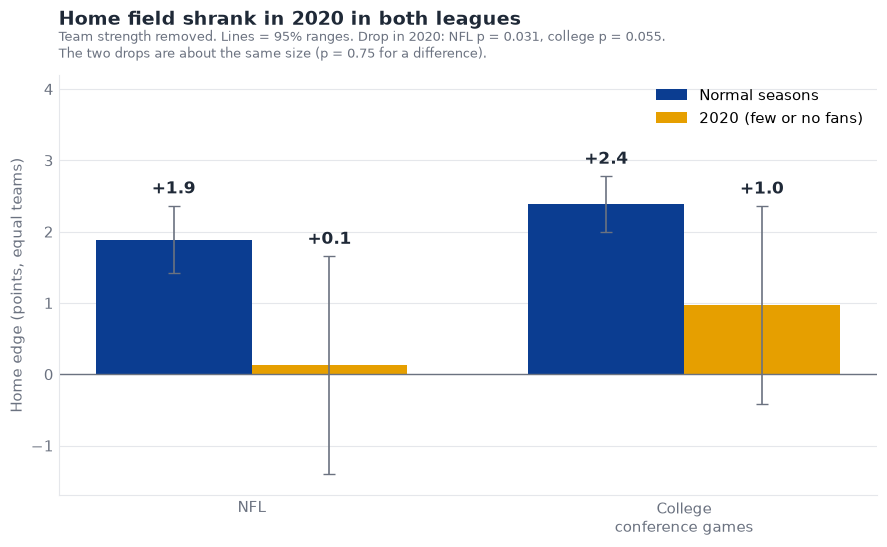

In [15]:
# Chart 8: strength-adjusted home edge, normal seasons vs. 2020, with 95% ranges
order = ["NFL", "College (conference)"]
labels = ["NFL", "College\nconference games"]
x = range(len(order)); w = 0.36
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for off, per, color, name in [(-w / 2, "normal", BLUE, "Normal seasons"), (w / 2, "2020", ORANGE, "2020 (few or no fans)")]:
    r = A.xs(per, level="period").loc[order]
    xs = [i + off for i in x]
    ax.bar(xs, r.home_edge_pts, w, color=color, label=name)
    ax.errorbar(xs, r.home_edge_pts, yerr=[r.home_edge_pts - r.low_95, r.high_95 - r.home_edge_pts],
                fmt="none", ecolor=MUTED, capsize=4, lw=1.2)
    for xi, v, hi in zip(xs, r.home_edge_pts, r.high_95):
        ax.text(xi, hi + 0.12, f"{v:+.1f}", ha="center", va="bottom", color=INK, fontsize=12, fontweight="bold")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(list(x), labels)
ax.set_ylim(-1.7, 4.2); ax.set_ylabel("Home edge (points, equal teams)")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Home field shrank in 2020 in both leagues", loc="left", fontsize=14, fontweight="bold", pad=36)
ax.text(0, 1.03, f"Team strength removed. Lines = 95% ranges. Drop in 2020: NFL p = {nfl_drop[2]:.3f}, college p = {conf_drop[2]:.3f}.\n"
        f"The two drops are about the same size (p = {hfa.norm_p(did[0] / did[1]):.2f} for a difference).",
        transform=ax.transAxes, color=MUTED, fontsize=9.5, va="bottom")
tidy(ax); plt.tight_layout(); plt.savefig("charts/08_league_fan_effect.png", dpi=200); plt.show()

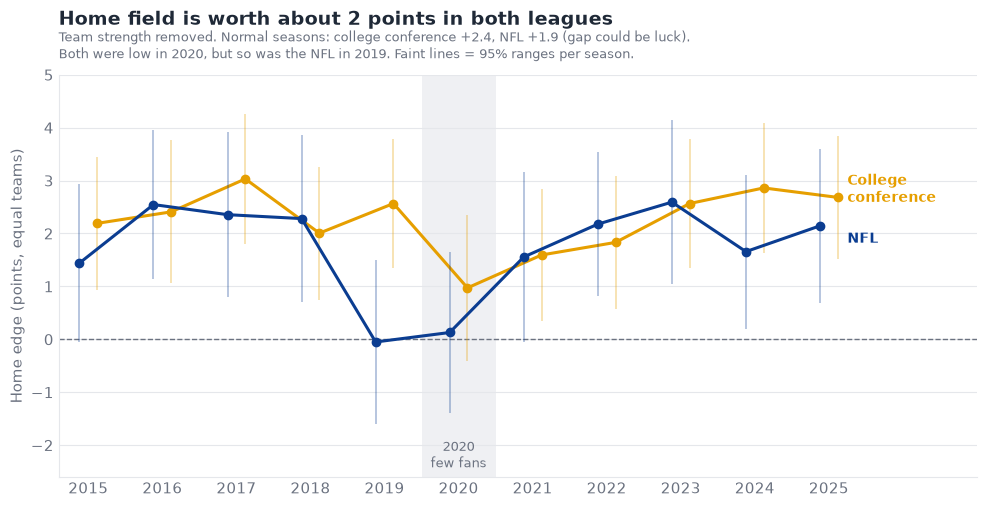

In [16]:
# Chart 9: strength-adjusted home edge by season, NFL vs. college conference games, 2020 shaded
s = season_edges.pivot(index="season", columns="group", values="home_edge")
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.axvspan(2019.5, 2020.5, color=GRID, alpha=0.6, lw=0)
ax.text(2020, -2.5, "2020\nfew fans", ha="center", va="bottom", color=MUTED, fontsize=9)
ax.axhline(0, ls="--", color=MUTED, lw=1)
se = season_edges.pivot(index="season", columns="group", values="se")
for name, color, nudge in [("College (conference)", ORANGE, 0.12), ("NFL", BLUE, -0.12)]:
    ax.errorbar(s.index + nudge, s[name], yerr=1.96 * se[name], fmt="none", ecolor=color, alpha=0.35, lw=1.2)
    ax.plot(s.index + nudge, s[name], color=color, lw=2.2, marker="o", ms=6)
ax.text(2025.25, s.loc[2025, "College (conference)"] + 0.15, "College\nconference", color=ORANGE, va="center", fontsize=10, fontweight="bold")
ax.text(2025.25, s.loc[2025, "NFL"] - 0.25, "NFL", color=BLUE, va="center", fontsize=10, fontweight="bold")
ax.set_xlim(2014.6, 2027.0); ax.set_ylim(-2.6, 5)
ax.set_xticks(range(2015, 2026)); ax.set_ylabel("Home edge (points, equal teams)")
n_avg = A.loc[("NFL", "normal"), "home_edge_pts"]; c_avg = A.loc[("College (conference)", "normal"), "home_edge_pts"]
ax.set_title("Home field is worth about 2 points in both leagues", loc="left", fontsize=14, fontweight="bold", pad=36)
ax.text(0, 1.03, f"Team strength removed. Normal seasons: college conference +{c_avg:.1f}, NFL +{n_avg:.1f} "
        f"(gap could be luck).\nBoth were low in 2020, but so was the NFL in 2019. Faint lines = 95% ranges per season.", transform=ax.transAxes, color=MUTED, fontsize=9.5, va="bottom")
tidy(ax); plt.tight_layout(); plt.savefig("charts/09_league_by_season.png", dpi=200); plt.show()

## Findings
- **Home field is worth about 2 points in both leagues.** With team strength removed, normal seasons: college conference games **+2.4 pts** (95% range 2.0–2.8), NFL **+1.9 pts** (1.4–2.4). Between two equally good teams, that's a home win **56.6%** vs. **56.2%** of the time. College is a little higher, but the gap could be luck (p = 0.11).
- **College only looks much bigger because of scheduling.** Across all FBS games home teams won **58.6%**, but in non-conference games the home team starts about **7 points stronger** (and wins 66.8%). With strength removed, non-conference games show the same +2.4-point edge as conference games.
- **Home field shrank in 2020 in both leagues.** NFL: +1.9 → **+0.1 pts** (p = 0.03). College conference games: +2.4 → **+1.0 pts** (p = 0.055, just short of the usual 0.05 bar); all FBS games: +2.4 → +0.8 (p = 0.02). The two leagues' drops are about the same size (p = 0.75 for a difference), so there's no evidence that fans matter more in one league.
- **That fits a crowd effect, but doesn't prove one.** It's one season, and the NFL's 2019 edge (−0.05 pts, with full stadiums) was just as low as 2020's.
- **Raw win % hid the college drop.** College conference home teams still won 55.8% in 2020. Partly because they were slightly stronger than their visitors that year (+0.5 pts vs. +0.1 normally), and partly ordinary noise: with 437 games, a season's win % has a 95% range of about ±4.7 points.
- **College crowd size in 2020 tells us little.** Bigger crowds went with bigger home edges (+0.7 pts per 10,000 fans, p = 0.42), but crowd size mostly reflects conference rules; comparing games within the same conference, the trend nearly disappears (+0.3, p = 0.83).

**Limitations**
- 2020 is one season, and college teams played only 3–12 games, so 2020 estimates are noisy (wide 95% ranges).
- "2020" means fewer fans, not zero: many college stadiums allowed partial crowds, and a few NFL stadiums did too. Recorded attendance of 0 may sometimes mean "not recorded".
- 2020 college schedules were mostly conference games, and some conferences played shortened seasons.
- The usual-stadium rule leans on the API's venue labels, which are sometimes inconsistent, so a few genuine home games are dropped (21 games in total; the effect on results is negligible).
- Conference title games before 2022 are found by date, not by an official label.